# Sesión 1 · Lab: del texto a los números
**Herramientas para el Procesamiento de Lenguaje Natural**

En la teoría vimos que el lenguaje tiene niveles (morfología, sintaxis, semántica, pragmática) y que una computadora no ve nada de eso: ve **números**. Hoy construimos, desde cero, el primer puente entre las dos cosas.

Las celdas marcadas con ✏️ son ejercicios para el equipo. Las preguntas marcadas con 💬 se responden en la celda de reflexión del final.

In [2]:
import re
import unicodedata
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

pd.set_option("display.max_columns", 30)

---
## Parte 0 · El corpus

Usamos libros de **dominio público** en español de [Project Gutenberg](https://www.gutenberg.org/). Son cuatro autores de épocas y lugares distintos, que es justo lo que necesitamos para hablar de estilo:

| Autor | Obra | País y época | ID de Gutenberg |
|---|---|---|---|
| Miguel de Cervantes | *Don Quijote de la Mancha* | España, 1605–1615 | 2000 |
| Benito Pérez Galdós | *Marianela* | España, 1878 | 17340 |
| Emilia Pardo Bazán | *Los pazos de Ulloa* | España, 1886 | 18005 |
| Horacio Quiroga | *Cuentos de amor de locura y de muerte* | Uruguay, 1917 | 13507 |

La función `descargar_libro` guarda una copia en la carpeta `corpus/`. Si Gutenberg no responde, sube tú los `.txt` a esa carpeta con el nombre `pg<ID>.txt` y la función los usará sin descargar nada.

In [3]:
LIBROS = {
    "Cervantes":   2000,
    "Galdós":      17340,
    "Pardo Bazán": 18005,
    "Quiroga":     13507,
}

CARPETA = Path("corpus")
CARPETA.mkdir(exist_ok=True)

def quitar_encabezado_gutenberg(texto):
    # Gutenberg agrega una licencia en inglés al inicio y al final; la quitamos.
    inicio = re.search(r"\*\*\* ?START OF (THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*", texto, re.I | re.S)
    fin = re.search(r"\*\*\* ?END OF (THE|THIS) PROJECT GUTENBERG EBOOK", texto, re.I)
    a = inicio.end() if inicio else 0
    b = fin.start() if fin else len(texto)
    return texto[a:b].strip()

def descargar_libro(id_libro):
    archivo = CARPETA / f"pg{id_libro}.txt"
    if not archivo.exists():
        urls = [f"https://www.gutenberg.org/cache/epub/{id_libro}/pg{id_libro}.txt",
                f"https://www.gutenberg.org/files/{id_libro}/{id_libro}-0.txt"]
        for url in urls:
            try:
                r = requests.get(url, timeout=30)
                if r.status_code == 200:
                    archivo.write_bytes(r.content)
                    break
            except requests.RequestException:
                pass
        else:
            raise RuntimeError(f"No pude descargar {id_libro}. Sube corpus/pg{id_libro}.txt a mano.")
    texto = archivo.read_bytes().decode("utf-8", errors="replace")
    return quitar_encabezado_gutenberg(texto)

textos = {autor: descargar_libro(i) for autor, i in LIBROS.items()}

for autor, t in textos.items():
    print(f"{autor:12s} {len(t):>10,} caracteres  {len(t.split()):>9,} palabras (aprox.)")

Cervantes     2,148,396 caracteres    386,614 palabras (aprox.)
Galdós          300,152 caracteres     50,537 palabras (aprox.)
Pardo Bazán     502,851 caracteres     83,416 palabras (aprox.)
Quiroga         300,544 caracteres     49,372 palabras (aprox.)


In [4]:
print(textos["Cervantes"][:800])

El ingenioso hidalgo don Quijote de la Mancha



por Miguel de Cervantes Saavedra





El ingenioso hidalgo don Quijote de la Mancha


  
Tasa

  
Testimonio de las erratas

  
El Rey

  
Al Duque de Béjar

  
Prólogo

  
Al libro de don Quijote de la Mancha



Que trata de la condición y ejercicio del famoso
hidalgo don Quijote de la Mancha

Que trata de la primera salida que de su tierra hizo
el ingenioso don Quijote

Donde se cuenta la graciosa manera que tuvo don
Quijote en armarse caballero

De lo que le sucedió a nuestro caballero cuando salió
de la venta

Donde se prosigue la narración de la desgracia de
nuestro caballero

Del donoso y grande escrutinio que el cura y el
barbero hicieron en la librería de nuestro ingenioso hidalgo

D


---
## Parte 1 · El texto son bytes

Para la computadora, cada carácter es un número (un *code point* de **Unicode**) y cada número se guarda como uno o varios **bytes** (con la codificación **UTF-8**). El español ya rompe la idea de "un carácter = un byte".

In [5]:
for ch in ["a", "ñ", "é", "¿", "爱", "😂"]:
    b = ch.encode("utf-8")
    print(f"{ch!r:6} code point U+{ord(ch):05X}   bytes en UTF-8: {len(b)}  {b}")

'a'    code point U+00061   bytes en UTF-8: 1  b'a'
'ñ'    code point U+000F1   bytes en UTF-8: 2  b'\xc3\xb1'
'é'    code point U+000E9   bytes en UTF-8: 2  b'\xc3\xa9'
'¿'    code point U+000BF   bytes en UTF-8: 2  b'\xc2\xbf'
'爱'    code point U+07231   bytes en UTF-8: 3  b'\xe7\x88\xb1'
'😂'    code point U+1F602   bytes en UTF-8: 4  b'\xf0\x9f\x98\x82'


### La misma letra, dos representaciones

La "é" se puede escribir como **un** carácter (é) o como **dos**: una "e" más un acento combinable. Se ven idénticas, pero para Python no son iguales. Esto pasa de verdad cuando copias texto de PDFs o de distintos sistemas operativos.

In [6]:
compuesta = "café"            # é como un solo carácter
descompuesta = "café"        # e + acento combinable

print(compuesta, descompuesta)
print("¿Iguales?", compuesta == descompuesta)
print("Longitudes:", len(compuesta), len(descompuesta))

nfc = lambda s: unicodedata.normalize("NFC", s)
print("¿Iguales tras normalizar a NFC?", nfc(compuesta) == nfc(descompuesta))

café café
¿Iguales? False
Longitudes: 4 5
¿Iguales tras normalizar a NFC? True


### ✏️ Ejercicio 1 · ¿Quitamos los acentos?

Muchos tutoriales quitan los acentos "para simplificar". Corre la celda y discutan en equipo: ¿qué se pierde?

In [7]:
def quitar_acentos(s):
    s = unicodedata.normalize("NFD", s)
    return "".join(c for c in s if unicodedata.category(c) != "Mn")   # Mn = marca combinable

for w in ["papá", "papa", "él", "el", "sé", "se", "más", "mas", "año", "ano"]:
    print(f"{w:5} → {quitar_acentos(w)}")

papá  → papa
papa  → papa
él    → el
el    → el
sé    → se
se    → se
más   → mas
mas   → mas
año   → ano
ano   → ano


💬 **Pregunta 1:** ¿Qué pares se volvieron indistinguibles? ¿En qué tarea sí convendría quitar acentos y en cuál sería un error? (Fíjense también en qué pasó con la ñ.)

---
## Parte 2 · ¿Qué es una palabra?

Parece obvio hasta que lo intentas programar. Probemos tokenizadores cada vez mejores sobre oraciones difíciles.

In [8]:
EJEMPLOS = [
    "¡Dámelo ya! ¿Lo trajiste del mercado o de Nueva York?",
    "Nimitztlazohtla.",                                    # náhuatl: "te amo", en una sola palabra
    "我爱你",                                               # chino: "te amo", sin espacios
    "Neta q está bien chido, jajajaja 😂 #NLP @profe",
    "Mándame el link del meeting a ana.lopez@correo.mx antes de las 6:30 p.m.",
    "El Sr. García pagó $1,250.50 el 20/11/2026.",
]

def tok_espacios(texto):
    return texto.split()

def tok_caracteres(texto):
    return list(texto)

for e in EJEMPLOS:
    print(tok_espacios(e))

['¡Dámelo', 'ya!', '¿Lo', 'trajiste', 'del', 'mercado', 'o', 'de', 'Nueva', 'York?']
['Nimitztlazohtla.']
['我爱你']
['Neta', 'q', 'está', 'bien', 'chido,', 'jajajaja', '😂', '#NLP', '@profe']
['Mándame', 'el', 'link', 'del', 'meeting', 'a', 'ana.lopez@correo.mx', 'antes', 'de', 'las', '6:30', 'p.m.']
['El', 'Sr.', 'García', 'pagó', '$1,250.50', 'el', '20/11/2026.']


Observa: `¡Dámelo` se queda pegado al signo, `York?` también, el chino es **una sola "palabra"** y el náhuatl también (¡aunque es una oración completa!). Por caracteres tendríamos el problema contrario: unidades sin significado.

In [10]:
print(tok_caracteres(EJEMPLOS[0])[:25])

['¡', 'D', 'á', 'm', 'e', 'l', 'o', ' ', 'y', 'a', '!', ' ', '¿', 'L', 'o', ' ', 't', 'r', 'a', 'j', 'i', 's', 't', 'e', ' ']


### Tokenizador con expresiones regulares

Versión 1: una palabra es una secuencia de caracteres de palabra (`\w+`) y cada signo de puntuación es su propio token.

In [11]:
def tok_regex_v1(texto):
    return re.findall(r"\w+|[^\w\s]", texto)

for e in EJEMPLOS:
    print(tok_regex_v1(e))

['¡', 'Dámelo', 'ya', '!', '¿', 'Lo', 'trajiste', 'del', 'mercado', 'o', 'de', 'Nueva', 'York', '?']
['Nimitztlazohtla', '.']
['我爱你']
['Neta', 'q', 'está', 'bien', 'chido', ',', 'jajajaja', '😂', '#', 'NLP', '@', 'profe']
['Mándame', 'el', 'link', 'del', 'meeting', 'a', 'ana', '.', 'lopez', '@', 'correo', '.', 'mx', 'antes', 'de', 'las', '6', ':', '30', 'p', '.', 'm', '.']
['El', 'Sr', '.', 'García', 'pagó', '$', '1', ',', '250', '.', '50', 'el', '20', '/', '11', '/', '2026', '.']


Mejor, pero ahora rompimos el correo, la hora, la cantidad, la abreviatura `Sr.` y el hashtag. Versión 2: describimos **primero** los casos especiales y **al final** el caso general. El orden importa: la regex toma la primera alternativa que encaja.

In [12]:
PATRON = re.compile(r'''
    [\w.+-]+@[\w-]+\.[\w.]+          # correos
  | https?://\S+                      # URLs
  | [#@]\w+                           # hashtags y menciones
  | \$?\d+(?:[.,:/]\d+)*              # números, horas, fechas y cantidades
  | (?:Sr|Sra|Dr|Dra|Lic|p\.m|a\.m)\. # algunas abreviaturas
  | \w+                               # palabras
  | [\U0001F300-\U0001FAFF☀-➿]   # emojis (rango aproximado)
  | [^\w\s]                           # cualquier otro signo
''', re.VERBOSE)

def tokenizar(texto, minusculas=False):
    tokens = PATRON.findall(texto)
    return [t.lower() for t in tokens] if minusculas else tokens

for e in EJEMPLOS:
    print(tokenizar(e))

['¡', 'Dámelo', 'ya', '!', '¿', 'Lo', 'trajiste', 'del', 'mercado', 'o', 'de', 'Nueva', 'York', '?']
['Nimitztlazohtla', '.']
['我爱你']
['Neta', 'q', 'está', 'bien', 'chido', ',', 'jajajaja', '😂', '#NLP', '@profe']
['Mándame', 'el', 'link', 'del', 'meeting', 'a', 'ana.lopez@correo.mx', 'antes', 'de', 'las', '6:30', 'p.m.']
['El', 'Sr.', 'García', 'pagó', '$1,250.50', 'el', '20/11/2026', '.']


### ¿Y los morfemas?

El español pega pronombres al verbo (**clíticos**: *dá-me-lo*, *cómpra-se-lo*) y contrae preposiciones (*del* = de + el). Intentemos separarlos con una regla ingenua.

In [13]:
CLITICOS = re.compile(r"^(\w{2,}?)((?:me|te|se|nos|os|lo|la|los|las|le|les)+)$")

def separar_morfemas(token):
    if token.lower() == "del":
        return ["de", "el"]
    if token.lower() == "al":
        return ["a", "el"]
    m = CLITICOS.match(token)
    if not m:
        return [token]
    raiz, pegados = m.groups()
    return [raiz] + re.findall(r"nos|os|les|los|las|me|te|se|lo|la|le", pegados)

for w in ["dámelo", "cómpraselo", "dile", "del", "calle", "sola", "pelo", "hielo", "escuela"]:
    print(f"{w:11} → {separar_morfemas(w)}")

dámelo      → ['dá', 'me', 'lo']
cómpraselo  → ['cómpra', 'se', 'lo']
dile        → ['di', 'le']
del         → ['de', 'el']
calle       → ['cal', 'le']
sola        → ['so', 'la']
pelo        → ['pe', 'lo']
hielo       → ['hie', 'lo']
escuela     → ['escue', 'la']


La regla funciona con *dámelo* y *cómpraselo*, pero destroza *calle*, *sola*, *pelo* o *escuela*: la forma no basta, hace falta saber **qué es un verbo**. Esto es exactamente lo que vimos en morfología: separar morfemas requiere conocimiento de la lengua, no solo patrones.

### ✏️ Ejercicio 2 · Mejora el tokenizador
1. Agrega a `PATRON` un caso para risas (`jajaja`, `jsjsjs`, `jajajajaja` deberían quedar como un solo token normalizado, por ejemplo `<RISA>`).
2. Encuentra **dos oraciones reales** (de redes sociales, WhatsApp o un periódico) donde tu tokenizador todavía falle y explica por qué falla.

💬 **Pregunta 2:** ¿Por qué el tokenizador por espacios no sirve para el náhuatl ni para el chino? Respóndelo con lo que vimos de tipología morfológica (aislante, flexiva, aglutinante, polisintética).

In [ ]:
# ✏️ Tu versión del tokenizador (copia PATRON y modifícalo aquí)

---
## Parte 3 · Vocabulario y palabras fuera de vocabulario (OOV)

El **vocabulario** es la lista de tokens distintos que el modelo conoce. Cualquier palabra que no esté ahí es **OOV** (*out of vocabulary*) y se reemplaza por un token especial `<UNK>`.

Pregunta: si construimos el vocabulario con *todo el Quijote*, ¿cuántas palabras de los otros autores no conoce?

In [15]:
def solo_palabras(texto):
    # Tokens alfabéticos en minúsculas (sin números ni signos)
    return [t for t in tokenizar(texto, minusculas=True) if t.isalpha()]

tokens = {autor: solo_palabras(t) for autor, t in textos.items()}

def construir_vocabulario(lista_tokens, min_frec=1):
    conteo = Counter(lista_tokens)
    vocab = {"<UNK>": 0}
    for palabra, f in conteo.most_common():
        if f >= min_frec:
            vocab[palabra] = len(vocab)
    return vocab

vocab_q = construir_vocabulario(tokens["Cervantes"])
print("Tamaño del vocabulario del Quijote:", f"{len(vocab_q):,}")

def tasa_oov(lista_tokens, vocab):
    return np.mean([t not in vocab for t in lista_tokens])

filas = []
for autor in LIBROS:
    if autor == "Cervantes":
        continue
    filas.append({
        "Autor": autor,
        "Tokens": len(tokens[autor]),
        "OOV (vocab. completo)": tasa_oov(tokens[autor], vocab_q),
        "OOV (solo palabras con frec. ≥ 2)": tasa_oov(tokens[autor], construir_vocabulario(tokens["Cervantes"], 2)),
    })
pd.DataFrame(filas).style.format({"OOV (vocab. completo)": "{:.1%}", "OOV (solo palabras con frec. ≥ 2)": "{:.1%}", "Tokens": "{:,}"})

Tamaño del vocabulario del Quijote: 22,944


,Autor,Tokens,OOV (vocab. completo),OOV (solo palabras con frec. ≥ 2)
0,Galdós,"50,904",13.1%,16.1%
1,Pardo Bazán,"83,513",17.5%,21.4%
2,Quiroga,"49,811",16.1%,19.2%


In [16]:
# ¿Qué palabras de Quiroga no aparecen en el Quijote?
desconocidas = Counter(t for t in tokens["Quiroga"] if t not in vocab_q)
print(desconocidas.most_common(40))

[('nébel', 109), ('fué', 74), ('usted', 67), ('mamá', 58), ('lidia', 53), ('elvira', 39), ('kassim', 34), ('vió', 33), ('embargo', 33), ('fiebre', 32), ('míster', 32), ('vd', 31), ('cayé', 30), ('murmuró', 29), ('podeley', 29), ('repuso', 27), ('mensú', 26), ('yaguaí', 26), ('fox', 25), ('vacas', 23), ('alazán', 23), ('malacara', 23), ('funes', 22), ('vezzera', 21), ('alambrado', 21), ('terrier', 21), ('recuerdo', 20), ('delirio', 20), ('benincasa', 20), ('ayestarain', 20), ('rabioso', 19), ('vigas', 19), ('anterior', 19), ('inés', 19), ('obraje', 19), ('cooper', 19), ('bruscamente', 18), ('sonrisa', 18), ('cocaína', 18), ('jones', 18)]


💬 **Pregunta 3:** Clasifica las palabras desconocidas: ¿cuántas son palabras nuevas de verdad (objetos o conceptos que no existían en 1605) y cuántas son **otra forma** de una palabra que el Quijote sí tiene (otra conjugación, otro género, otro número)? ¿Qué nos dice eso de la morfología del español?

---
## Parte 4 · Ley de Zipf

George Zipf observó en 1935 que, en cualquier texto, la frecuencia de una palabra es aproximadamente inversamente proporcional a su posición en el ranking:

$$f(r) \propto \frac{1}{r^{\alpha}}, \quad \alpha \approx 1$$

La palabra más común aparece el doble que la segunda, el triple que la tercera... Comprobémoslo.

In [17]:
conteo_q = Counter(tokens["Cervantes"])
print("Las 20 palabras más frecuentes del Quijote:")
print(conteo_q.most_common(20))

hapax = sum(1 for f in conteo_q.values() if f == 1)
print(f"\nHapax legomena (palabras que aparecen UNA sola vez): {hapax:,} de {len(conteo_q):,} ({hapax/len(conteo_q):.0%} del vocabulario)")

Las 20 palabras más frecuentes del Quijote:
[('que', 20769), ('de', 18410), ('y', 18272), ('la', 10492), ('a', 9876), ('en', 8285), ('el', 8265), ('no', 6346), ('los', 4769), ('se', 4752), ('con', 4275), ('por', 3945), ('lo', 3492), ('las', 3486), ('le', 3420), ('su', 3388), ('don', 2714), ('del', 2536), ('me', 2345), ('como', 2270)]

Hapax legomena (palabras que aparecen UNA sola vez): 11,151 de 22,943 (49% del vocabulario)


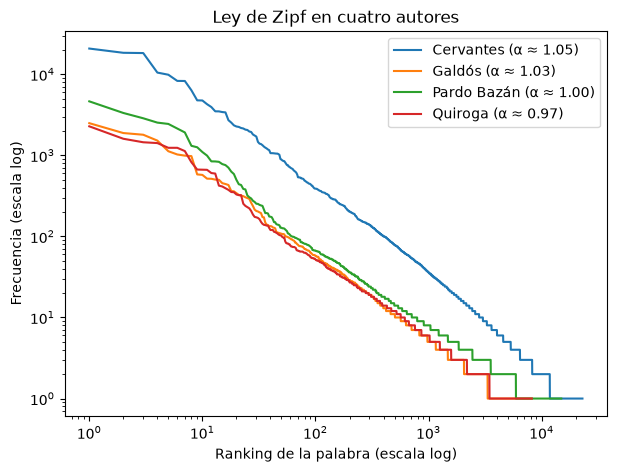

In [18]:
fig, ax = plt.subplots(figsize=(7, 5))
for autor, toks in tokens.items():
    frec = np.array(sorted(Counter(toks).values(), reverse=True))
    rango = np.arange(1, len(frec) + 1)
    pendiente, _ = np.polyfit(np.log(rango[:1000]), np.log(frec[:1000]), 1)
    ax.loglog(rango, frec, label=f"{autor} (α ≈ {-pendiente:.2f})")
ax.set_xlabel("Ranking de la palabra (escala log)")
ax.set_ylabel("Frecuencia (escala log)")
ax.set_title("Ley de Zipf en cuatro autores")
ax.legend()
plt.show()

💬 **Pregunta 4:** Las palabras de arriba del ranking (*de, que, la, y, el...*) no dicen nada del tema del libro. ¿Las quitarías?

---
## Parte 5 · Bolsa de palabras (*Bag of Words*) desde cero

La idea: representar cada documento como un **vector de conteos**, una posición por cada palabra del vocabulario. El orden de las palabras desaparece.

In [19]:
docs = [
    "El perro mordió al hombre",
    "El hombre mordió al perro",
    "El perro ladró y el hombre corrió",
]

def bow(documentos, vocab=None):
    tok_docs = [solo_palabras(d) for d in documentos]
    if vocab is None:
        vocab = sorted(set(t for d in tok_docs for t in d))
    indice = {w: j for j, w in enumerate(vocab)}
    X = np.zeros((len(documentos), len(vocab)), dtype=np.int32)
    for i, d in enumerate(tok_docs):
        for t in d:
            if t in indice:
                X[i, indice[t]] += 1
    return X, vocab

X, vocab_mini = bow(docs)
display(pd.DataFrame(X, columns=vocab_mini, index=[f"doc {i}" for i in range(len(docs))]))
print("¿El doc 0 y el doc 1 tienen el mismo vector?", np.array_equal(X[0], X[1]))

,al,corrió,el,hombre,ladró,mordió,perro,y
doc 0,1,0,1,1,0,1,1,0
doc 1,1,0,1,1,0,1,1,0
doc 2,0,1,2,1,1,0,1,1


¿El doc 0 y el doc 1 tienen el mismo vector? True


*El perro mordió al hombre* y *El hombre mordió al perro* quedan **idénticos**. La bolsa de palabras no sabe quién mordió a quién: perdimos la sintaxis.

Ahora a escala real: partimos cada libro en fragmentos de 1,000 palabras y armamos la matriz documento-término completa.

In [20]:
def fragmentar(toks, n=1000):
    return [toks[i:i + n] for i in range(0, len(toks) - n + 1, n)]

fragmentos = [" ".join(f) for toks in tokens.values() for f in fragmentar(toks)]
X_grande, vocab_grande = bow(fragmentos)

ceros = 1 - np.count_nonzero(X_grande) / X_grande.size
print(f"Matriz: {X_grande.shape[0]} fragmentos × {X_grande.shape[1]:,} palabras")
print(f"Celdas en cero: {ceros:.1%}")
print(f"Memoria como matriz densa: {X_grande.nbytes / 1e6:.0f} MB")

Matriz: 565 fragmentos × 36,232 palabras
Celdas en cero: 98.8%
Memoria como matriz densa: 82 MB


💬 **Pregunta 5:** Casi toda la matriz son ceros (matriz **dispersa**). ¿Por qué pasa esto? Relaciónalo con la ley de Zipf. ¿Qué información lingüística perdemos al usar BoW? Den al menos tres ejemplos con oraciones propias.

---
## Parte 6 · Huella estilística: ¿quién lo escribió?

En 1964, Frederick Mosteller y David Wallace resolvieron un misterio histórico: quién había escrito 12 de los *Federalist Papers* cuya autoría se disputaban Alexander Hamilton y James Madison. No usaron el tema de los textos, sino **la frecuencia de palabras funcionales** como *upon*, *by* o *to*. Esas palabras se usan sin pensar, y por eso son una huella difícil de falsificar.

Vamos a replicar la idea con un método clásico, el **Delta de Burrows** (2002):
1. Partimos cada libro en fragmentos.
2. Para cada fragmento contamos la frecuencia relativa de ~100 palabras funcionales (una bolsa de palabras con vocabulario restringido).
3. Estandarizamos (z-scores) y asignamos cada fragmento de prueba al autor cuyo "perfil promedio" esté más cerca.

In [21]:
PALABRAS_FUNCION = '''
de la que el en y a los se del las un por con no una su para es al lo como más pero sus le ya o
este sí porque esta entre cuando muy sin sobre también me hasta hay donde quien desde todo nos
durante todos uno les ni contra otros ese eso ante ellos e esto mí antes algunos qué unos yo otro
otras otra él tanto esa estos mucho quienes nada muchos cual poco ella estar estas algunas algo
nosotros mi mis tú te ti tu tus ellas nosotras os mío mía tuyo suyo cuanto aunque pues mientras
'''.split()
print(len(PALABRAS_FUNCION), "palabras funcionales")

rng = np.random.default_rng(42)

def preparar_datos(n=1000, max_frag=60):
    frs, etiquetas = [], []
    for autor, toks in tokens.items():
        f = fragmentar(toks, n)
        rng.shuffle(f)
        f = f[:max_frag]                      # mismo número de fragmentos por autor (balance)
        frs += f
        etiquetas += [autor] * len(f)
    return frs, np.array(etiquetas)

def matriz_frecuencias(frs, vocab):
    indice = {w: j for j, w in enumerate(vocab)}
    X = np.zeros((len(frs), len(vocab)))
    for i, f in enumerate(frs):
        for t in f:
            j = indice.get(t)
            if j is not None:
                X[i, j] += 1
        X[i] /= len(f)                         # frecuencia relativa
    return X

def delta_burrows(X_tr, y_tr, X_te):
    mu, sd = X_tr.mean(0), X_tr.std(0) + 1e-9
    Z_tr, Z_te = (X_tr - mu) / sd, (X_te - mu) / sd
    autores = np.unique(y_tr)
    centroides = np.stack([Z_tr[y_tr == a].mean(0) for a in autores])
    distancias = np.abs(Z_te[:, None, :] - centroides[None, :, :]).mean(2)   # Delta = distancia media absoluta
    return autores[distancias.argmin(1)]

def evaluar(vocab, n=1000):
    frs, y = preparar_datos(n)
    idx = rng.permutation(len(y))
    corte = int(0.7 * len(y))
    tr, te = idx[:corte], idx[corte:]
    X = matriz_frecuencias(frs, vocab)
    pred = delta_burrows(X[tr], y[tr], X[te])
    return np.mean(pred == y[te]), y[te], pred

acc, y_real, y_pred = evaluar(PALABRAS_FUNCION)
print(f"Exactitud con {len(PALABRAS_FUNCION)} palabras funcionales: {acc:.1%}")
pd.crosstab(pd.Series(y_real, name="Real"), pd.Series(y_pred, name="Predicho"))

102 palabras funcionales
Exactitud con 102 palabras funcionales: 83.3%


Predicho,Cervantes,Galdós,Pardo Bazán,Quiroga
Real,,,,
Cervantes,18,0,2,0
Galdós,0,7,4,1
Pardo Bazán,0,0,21,0
Quiroga,0,0,4,9


### ¿Y si usamos las palabras de contenido?

Probemos con las 300 palabras más frecuentes que **no** son funcionales. Debería funcionar mejor.

In [22]:
todas = Counter(t for toks in tokens.values() for t in toks)
contenido = [w for w, _ in todas.most_common(2000) if w not in set(PALABRAS_FUNCION)][:300]
acc_c, _, _ = evaluar(contenido)
print(f"Exactitud con 300 palabras de contenido: {acc_c:.1%}")
print("Algunas de esas palabras:", contenido[:40])

Exactitud con 300 palabras de contenido: 69.7%
Algunas de esas palabras: ['don', 'si', 'quijote', 'sancho', 'dijo', 'había', 'tan', 'ha', 'bien', 'era', 'así', 'señor', 'ser', 'respondió', 'dos', 'merced', 'vuestra', 'sino', 'fue', 'aquí', 'dios', 'he', 'caballero', 'decir', 'está', 'estaba', 'aquel', 'hacer', 'ojos', 'allí', 'casa', 'señora', 'cosa', 'son', 'ver', 'mal', 'tenía', 'ahora', 'tiene', 'verdad']


💬 **Pregunta 6:** Revisa la lista de palabras de contenido: aparecen nombres de personajes (*sancho*, *quijote*...). ¿El modelo está aprendiendo **el estilo** del autor o **de qué libro** viene el fragmento? ¿Funcionaría con otro libro del mismo autor? Esto se llama **fuga de información** (*data leakage*) y es el error número uno en atribución de autoría.

In [24]:
# ¿Qué palabras funcionales distinguen a cada autor? (z-score promedio más alto)
frs, y = preparar_datos(1000)
X = matriz_frecuencias(frs, PALABRAS_FUNCION)
Z = (X - X.mean(0)) / (X.std(0) + 1e-9)
for autor in LIBROS:
    z = Z[y == autor].mean(0)
    top = np.argsort(z)[::-1][:6]
    bajo = np.argsort(z)[:4]
    print(f"{autor:12s} usa MÁS: {', '.join(PALABRAS_FUNCION[j] for j in top):40s} usa MENOS: {', '.join(PALABRAS_FUNCION[j] for j in bajo)}")

Cervantes    usa MÁS: que, y, porque, quien, os, aunque        usa MENOS: un, una, la, al
Galdós       usa MÁS: tú, te, yo, qué, ti, tu                  usa MENOS: le, y, el, se
Pardo Bazán  usa MÁS: se, la, del, el, de, al                  usa MENOS: mi, yo, ella, que
Quiroga      usa MÁS: pero, un, durante, sobre, esa, su        usa MENOS: que, y, le, estas


### ✏️ Ejercicio 3 · ¿Cuánto texto necesitas para reconocer a alguien?
Corre la celda y explica la curva. ¿A partir de cuántas palabras el método es confiable? ¿Como podrías aplicarlo a un tuit (≈ 30 palabras)?

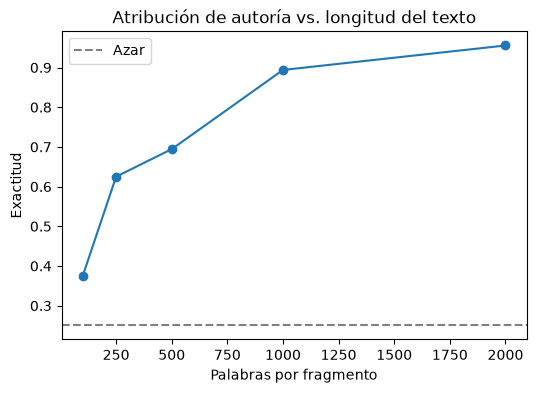

In [25]:
tamanos = [100, 250, 500, 1000, 2000]
exactitudes = [evaluar(PALABRAS_FUNCION, n)[0] for n in tamanos]

plt.figure(figsize=(6, 4))
plt.plot(tamanos, exactitudes, marker="o")
plt.axhline(1 / len(LIBROS), ls="--", c="gray", label="Azar")
plt.xlabel("Palabras por fragmento")
plt.ylabel("Exactitud")
plt.title("Atribución de autoría vs. longitud del texto")
plt.legend()
plt.show()

---
## Parte 7 · Lo mismo, con una librería (NLTK)

Ahora que sabemos qué hay por dentro, veamos qué nos da **NLTK**. Ojo: el etiquetador gramatical y el lematizador de NLTK **solo funcionan en inglés**; para español se usa spaCy.

In [26]:
import nltk
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import SnowballStemmer

for e in EJEMPLOS[:4]:
    print(word_tokenize(e, language="spanish"))

print(sent_tokenize("El Sr. García llegó tarde. ¿Por qué? Nadie lo sabe.", language="spanish"))

stemmer = SnowballStemmer("spanish")
print([stemmer.stem(w) for w in ["canto", "cantaríamos", "cantásemos", "cantante", "canción", "dámelo"]])

['¡Dámelo', 'ya', '!', '¿Lo', 'trajiste', 'del', 'mercado', 'o', 'de', 'Nueva', 'York', '?']
['Nimitztlazohtla', '.']
['我爱你']
['Neta', 'q', 'está', 'bien', 'chido', ',', 'jajajaja', '😂', '#', 'NLP', '@', 'profe']
['El Sr. García llegó tarde.', '¿Por qué?', 'Nadie lo sabe.']
['cant', 'cant', 'cant', 'cantant', 'cancion', 'damel']


💬 **Pregunta 7:** Compara `word_tokenize` con tu tokenizador. ¿En qué gana cada uno? ¿El *stemmer* entiende que *canción* y *canto* están relacionadas? ¿Qué hace con *dámelo*?

In [ ]:
# Bonus: lematización real en español con spaCy.
# En Colab, descomenta la siguiente línea la primera vez:
# !python -m spacy download es_core_news_sm
try:
    import spacy
    nlp = spacy.load("es_core_news_sm")
    doc = nlp("Dámelo ya, que los niños cantaríamos canciones mientras ella compraba pan.")
    print([(t.text, t.lemma_, t.pos_) for t in doc])
except Exception as err:
    print("spaCy o el modelo en español no están instalados todavía:", type(err).__name__)

[('Dámelo', 'Dámelo', 'PROPN'), ('ya', 'ya', 'ADV'), (',', ',', 'PUNCT'), ('que', 'que', 'SCONJ'), ('los', 'el', 'DET'), ('niños', 'niño', 'NOUN'), ('cantaríamos', 'cantaríar', 'VERB'), ('canciones', 'canción', 'NOUN'), ('mientras', 'mientras', 'SCONJ'), ('ella', 'él', 'PRON'), ('compraba', 'comprar', 'VERB'), ('pan', 'pan', 'NOUN'), ('.', '.', 'PUNCT')]


---
## 📦 Entregable del equipo

En **este mismo notebook**:
1. Ejercicios ✏️ 1, 2 y 3 resueltos.
2. Las preguntas 💬 1 a 7 respondidas en la celda de abajo (dos a cinco líneas cada una).
3. **Proyecto Identificación de autoría, avance 1:** cambia el diccionario `LIBROS` por el corpus de su equipo (sus propios autores) y vuelve a correr las Partes 3, 4 y 6. Comenten qué cambió.

### 💬 Reflexión del equipo
*Escriban aquí sus respuestas.*

1.
2.
3.
4.
5.
6.
7.